In [ ]:
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "CMakeLists.txt").is_file() and (p / "src/atspmv.cu").is_file())


In [10]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import datetime
%matplotlib inline


In [18]:
data = pd.read_csv(ROOT / "results/csv/fullresbsr.csv")
data.keys

<bound method NDFrame.keys of                     matrix    nrow    ncol       nnz  avg_nnz  min    max  \
0            08blocks.mtx      300     300       592     1.97    1     38   
1            1138_bus.mtx     1138    1138      4054     3.56    2     18   
2            12month1.mtx    12471  872622  22624727  1814.19    1  75355   
3              130bit.mtx      584     575      6120    10.48    6     14   
4                 144.mtx   144649  144649   2148786    14.86    4     26   
...                    ...     ...     ...       ...      ...  ...    ...   
2793       yeast_30NN.mtx     1484    1484     62350    42.01   30     75   
2794          young3c.mtx      841     841      3988     4.74    2      7   
2795              zed.mtx      116     142       666     5.74    1     12   
2796           zenios.mtx     2873    2873     27191     9.46    1     47   
2797  zeros_nopss_13k.mtx    13296   13296     48827     3.67    1     32   

      zero_len        stand  speedupcusp  spe

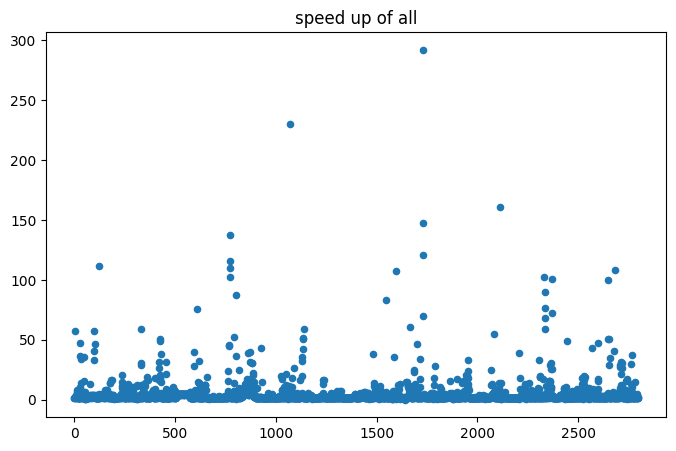

5.000489635453896

In [17]:
info = {
    'index': [i for i in range(len(data))],
    'speedup': data['speedupbsr'].values
}
# print(info)
df = pd.DataFrame(info)
# 绘制散点图
df.plot(kind='scatter', x='index', y='speedup', title='speed up of all', xlabel='', ylabel='', figsize=(8, 5))
plt.show()
data['speedupbsr'].mean()

In [19]:
filtered_data = data[data['speedupbsr'] == 0.0]
# filtered_data = filtered_data[filtered_data[' stand'] < 12]
# filtered_data = filtered_data[filtered_data[' nrow'] < 6192]
# filtered_data = filtered_data[filtered_data[' speedup'] < 1.1]

# len(filtered_data)
filtered_data

,matrix,nrow,ncol,nnz,avg_nnz,min,max,zero_len,stand,speedupcusp,speedupbsr,speedupdasp,speedupamg,gflopscusp,gflopsbsr,gflopsdasp,gflopsamgt,gflopsdy,pass


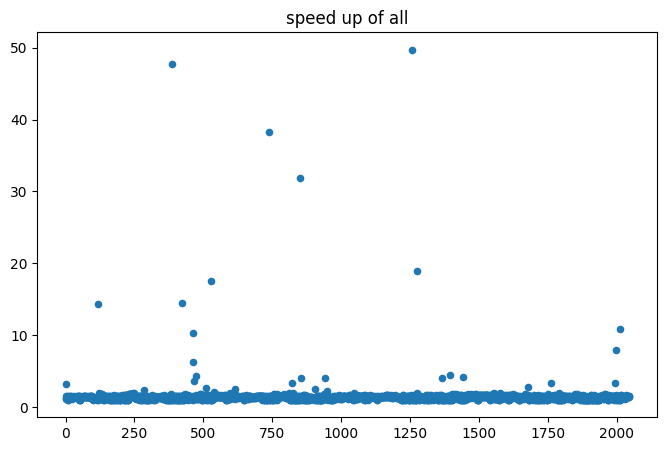

1.4931182795698925

In [4]:
specific_columns = ['tc2x1Baltime','tc1x2Baltime','tc2x1NoBal', 'tc1x2NoBal', 'csrbalTime','tc2x1NoBal','tc1x2NoBal', 'csrTime', 'tc1x2Level0']
max_values_specific = data[specific_columns].max(axis=1)
max_values_specific = [i for i in max_values_specific if i > 1]
info = {
    'index': [i for i in range(len(max_values_specific))],
    'speedup': max_values_specific
}
def isLessThan1(row):
    # 获取当前行中这四列的值
    values = row[specific_columns]
    # 检查csrTime是否为最大值
    return values.max() < 1.0
# tc2x1NoBalance = data[data.apply(isLessThan1, axis=1)]
# tc2x1NoBalance
# print(info)
df = pd.DataFrame(info)
# # 绘制散点图
df.plot(kind='scatter', x='index', y='speedup', title='speed up of all', xlabel='', ylabel='', figsize=(8, 5))
plt.show()
import numpy as np
np.mean(max_values_specific)

In [ ]:
specific_columns = ['tc2x1Baltime','tc1x2Baltime','tc2x1NoBal', 'tc1x2NoBal', 'csrbalTime','tc2x1NoBal','tc1x2NoBal', 'csrTime', 'tc1x2Level0']
def is_tc2x1NoBalance_time_max(row):
    # 获取当前行中这四列的值
    values = row[specific_columns]
    # 检查csrTime是否为最大值
    return values.max() == row['tc1x2Level0'] and values.max() != row['tc1x2Baltime'] and values.max() != row['tc2x1Baltime']
tc2x1NoBalance = data[data.apply(is_tc2x1NoBalance_time_max, axis=1)]
tc2x1NoBalance

,matrix,nrows,ncols,avg_nnz,minlen,maxlen,zerolen,stand,density0,dense2x1,dense1x2,tc2x1Baltime,tc1x2Baltime,csrbalTime,tc1x2NoBal,tc2x1NoBal,tc1x2Level0,csrTime
201,bcsstk02.mtx,66,66,66.00,66,66,0,0.000000,0.89,0.89,0.89,1.01,1.00,1.00,1.00,1.00,1.01,0.98
203,bcsstk04.mtx,132,132,27.64,15,46,0,10.750104,0.47,0.88,0.89,1.30,1.30,1.08,1.44,1.30,1.44,0.93
211,bcsstk12.mtx,1473,1473,23.25,2,33,0,6.736080,0.42,0.94,0.83,1.00,1.00,0.99,1.01,1.00,1.01,0.99
239,bcsstm01.mtx,48,48,1.00,1,1,0,0.000000,0.12,0.25,0.12,1.62,1.44,1.44,1.62,1.62,1.62,1.62
240,bcsstm02.mtx,66,66,1.00,1,1,0,0.000000,0.12,0.23,0.12,1.01,1.00,1.00,1.01,1.00,1.01,1.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2059,TSOPF_RS_b300_c3.mtx,42138,42138,104.74,1,209,0,102.443167,0.75,0.99,0.95,1.18,1.13,0.55,1.15,1.20,1.26,0.46
2064,TSOPF_RS_b678_c2.mtx,35696,35696,246.02,2,512,0,253.610815,0.87,1.00,0.99,1.09,1.02,0.35,1.05,1.05,1.28,0.32
2070,tube2.mtx,21498,21498,41.73,28,48,0,5.243812,0.55,0.96,0.91,1.03,1.02,1.00,1.02,1.02,1.03,1.00
2125,watt_2.mtx,1856,1856,6.22,1,128,0,3.155425,0.17,0.75,0.75,1.56,1.27,1.27,1.40,1.17,1.56,0.78


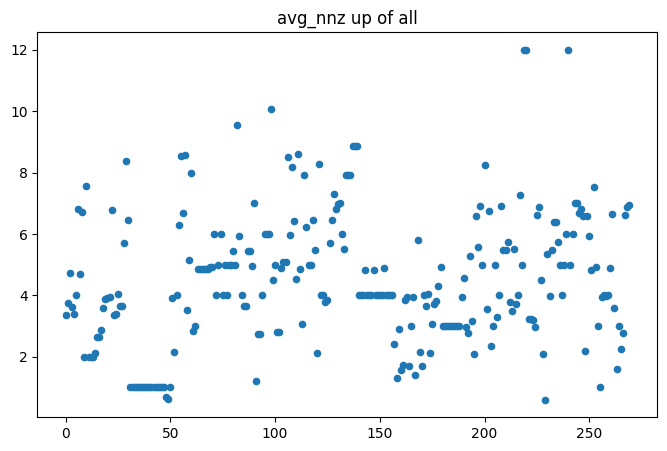

4.486148148148147

In [13]:
avg_nnz_info = {
    'index': [i for i in range(len(tc2x1NoBalance))],
    'avg_nnz': tc2x1NoBalance['avg_nnz']
}
avg_nnz_df = pd.DataFrame(avg_nnz_info)
# 绘制散点图
avg_nnz_df.plot(kind='scatter', x='index', y='avg_nnz', title='avg_nnz up of all', xlabel='', ylabel='', figsize=(8, 5))
plt.show()
tc2x1NoBalance['avg_nnz'].mean()

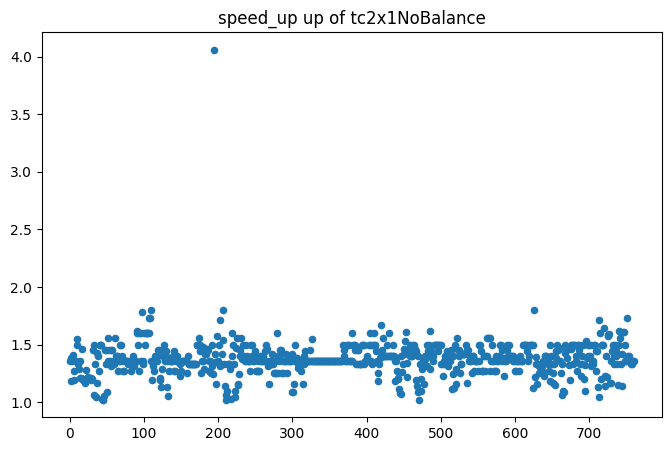

1.3760840998685937

In [10]:
avg_speed_info = {
    'index': [i for i in range(len(tc2x1NoBalance))],
    'speed_up': tc2x1NoBalance['tc2x1NoBalance']
}
avg_nnz_df = pd.DataFrame(avg_speed_info)
# 绘制散点图
avg_nnz_df.plot(kind='scatter', x='index', y='speed_up', title='speed_up up of tc2x1NoBalance', xlabel='', ylabel='', figsize=(8, 5))
plt.show()
tc2x1NoBalance['tc2x1NoBalance'].mean()

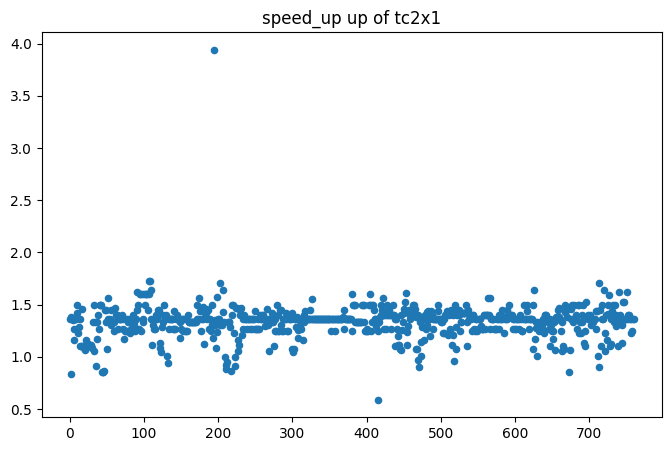

1.3364520367936925

In [11]:
avg_speed_info = {
    'index': [i for i in range(len(tc2x1NoBalance))],
    'speed_up': tc2x1NoBalance['tc2x1time']
}
avg_nnz_df = pd.DataFrame(avg_speed_info)
# 绘制散点图
avg_nnz_df.plot(kind='scatter', x='index', y='speed_up', title='speed_up up of tc2x1', xlabel='', ylabel='', figsize=(8, 5))
plt.show()
tc2x1NoBalance['tc2x1time'].mean()